# Análise dos datos

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv(
    "datos/clean/datos_limpios.csv",
    encoding="utf-8"
)

In [3]:
display(df.head())

,Data,Temp. media (ºC),Temp. mínima (ºC),Temp. máxima (ºC),Humidade relativa (%),Precipitación (mm),Vento medio (km/h),Presión (hPa)
0,2021-01-01,5.9,3.3,9.1,87,12.2,11.0,1015.7
1,2021-01-02,5.5,3.1,9.7,91,9.8,6.4,1019.8
2,2021-01-03,5.6,3.0,8.4,92,12.4,8.5,1018.9
3,2021-01-04,3.6,-0.3,6.8,92,4.7,7.8,1015.4
4,2021-01-05,2.8,-1.5,9.4,94,1.2,6.2,1014.6


In [4]:
df["Data"] = pd.to_datetime(df["Data"], errors="coerce")

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1812 entries, 0 to 1811
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Data                   1812 non-null   datetime64[us]
 1   Temp. media (ºC)       1812 non-null   float64       
 2   Temp. mínima (ºC)      1812 non-null   float64       
 3   Temp. máxima (ºC)      1812 non-null   float64       
 4   Humidade relativa (%)  1812 non-null   int64         
 5   Precipitación (mm)     1812 non-null   float64       
 6   Vento medio (km/h)     1812 non-null   float64       
 7   Presión (hPa)          1812 non-null   float64       
dtypes: datetime64[us](1), float64(6), int64(1)
memory usage: 113.4 KB


## 4.4 Cuestións

1. Cal foi a temperatura media de cada ano? Obsérvase algunha tendencia?
2. Cal é, de media, o mes máis chuvioso e o máis seco?
3. Cantos días de choiva hai cada mes? Considera día de choiva o que ten polo menos 1 mm (indica o criterio que uses).
4. Cal foi o día máis quente e o máis frío de cada ano?

### Temperatura media de cada ano

Calculamos a temperatura media para cada ano. Non parece observarse ningunha tendencia. Os valores de 2021 e de 2022 son os máis extremos. Probablemente se a gráfica contivese máis anos poderíamos apreciar algo de tendencia debida ao quentamento global, pero con só 5 anos non temos un periodo o suficientemente longo.

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# Asegurarnos de que Data é de tipo datetime
df["Data"] = pd.to_datetime(df["Data"], errors="coerce")

# Calcular a temperatura media de cada ano
temperatura_anual = df.groupby(
    df["Data"].dt.year
)["Temp. media (ºC)"].mean()

temperatura_anual.index.name = "Ano"

print(temperatura_anual.round(2))

Ano
2021    14.15
2022    15.00
2023    14.92
2024    14.44
2025    14.48
Name: Temp. media (ºC), dtype: float64


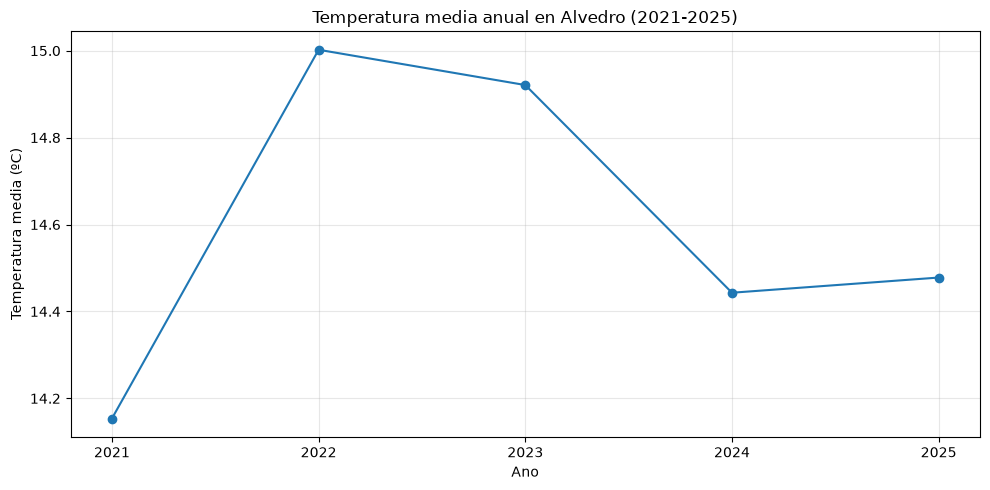

In [9]:
plt.figure(figsize=(10, 5))

plt.plot(
    temperatura_anual.index,
    temperatura_anual.values,
    marker="o",
    linewidth=1.5
)

plt.title("Temperatura media anual en Alvedro (2021-2025)")
plt.xlabel("Ano")
plt.ylabel("Temperatura media (ºC)")
plt.xticks(temperatura_anual.index)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Mes máis chuvioso e máis seco

Neste caso, imos calcular a precipitación media de cada mes do ano, agrupando os datos por mes e excluíndo xullo de 2023 para evitar que os 21 días sen rexistros distorsionen o resultado.

In [8]:
# Asegurarnos de que a data está en formato datetime
df["Data"] = pd.to_datetime(df["Data"], errors="coerce")

# Excluír xullo de 2023
df_filtrado = df[
    ~((df["Data"].dt.month == 7) & (df["Data"].dt.year == 2023))
].copy()

# Calcular a precipitación media para cada mes do ano
precipitacion_mensual = (
    df_filtrado.groupby(df_filtrado["Data"].dt.month)["Precipitación (mm)"]
    .mean()
)

print(precipitacion_mensual.round(2))

Data
1     4.06
2     3.45
3     2.77
4     2.73
5     2.15
6     1.73
7     0.51
8     0.44
9     2.49
10    4.77
11    5.08
12    4.42
Name: Precipitación (mm), dtype: float64


In [12]:
meses = {
    1: "Xaneiro", 2: "Febreiro", 3: "Marzo",
    4: "Abril", 5: "Maio", 6: "Xuño",
    7: "Xullo", 8: "Agosto", 9: "Setembro",
    10: "Outubro", 11: "Novembro", 12: "Decembro"
}

mes_chuvioso = precipitacion_mensual.idxmax()
mes_seco = precipitacion_mensual.idxmin()

print(
    f"Mes máis chuvioso: {meses[mes_chuvioso]} "
    f"({precipitacion_mensual[mes_chuvioso]:.2f} mm de media diaria)"
)

print(
    f"Mes máis seco: {meses[mes_seco]} "
    f"({precipitacion_mensual[mes_seco]:.2f} mm de media diaria)"
)

Mes máis chuvioso: Novembro (5.08 mm de media diaria)
Mes máis seco: Agosto (0.44 mm de media diaria)


O mes máis chuvioso é novembro e o máis seco agosto, aínda que con moi pouca diferenza sobre xullo. É unha pena non poder dispor dos datos de xullo do 2023 porque poderiamos mellorar esta comparativa.

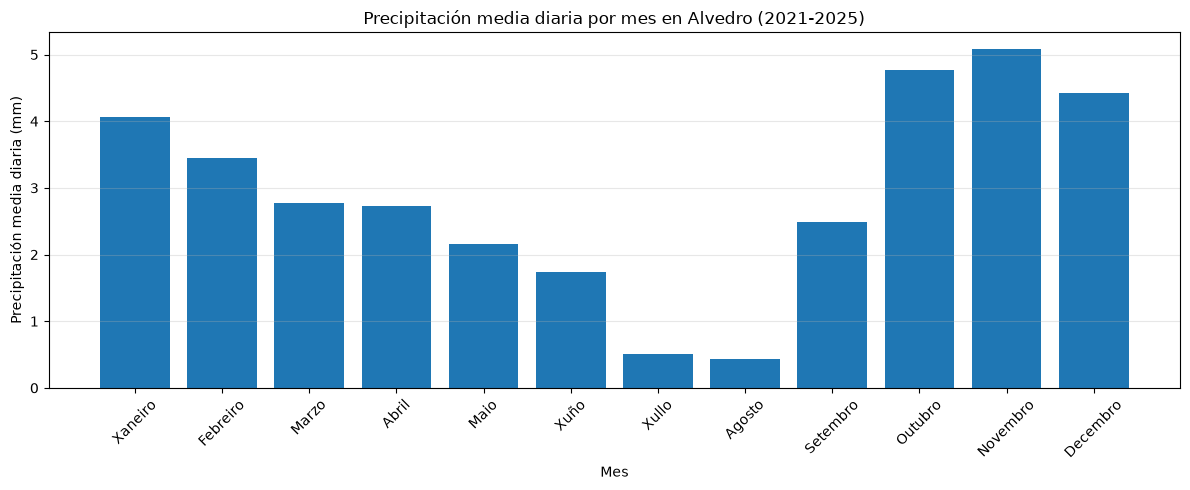

In [13]:
plt.figure(figsize=(12, 5))

plt.bar(
    [meses[m] for m in precipitacion_mensual.index],
    precipitacion_mensual.values
)

plt.title("Precipitación media diaria por mes en Alvedro (2021-2025)")
plt.xlabel("Mes")
plt.ylabel("Precipitación media diaria (mm)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Días de choiva por mes

Consideramos día de choiva aquel no que a precipitación é superior a 1 mm. 
A continuación, calculamos o número de días de choiva por mes e ano. Excluirase xullo do 2023 polas razóns expostas anteriormente. 

In [14]:
# Asegurarnos de que as columnas teñen o formato correcto
df["Data"] = pd.to_datetime(df["Data"], errors="coerce")

df["Precipitación (mm)"] = pd.to_numeric(
    df["Precipitación (mm)"],
    errors="coerce"
)

# Excluír xullo de 2023
df_filtrado = df[
    ~((df["Data"].dt.month == 7) & (df["Data"].dt.year == 2023))
].copy()

In [16]:
# Considerar día de choiva se a precipitación supera 1 mm
df_filtrado["Dia_chuvioso"] = (
    df_filtrado["Precipitación (mm)"] > 1
)

# Contar os días de choiva por ano e mes
dias_chuvia = (
    df_filtrado.groupby([
        df_filtrado["Data"].dt.year,
        df_filtrado["Data"].dt.month
    ])["Dia_chuvioso"]
    .sum()
    .unstack(level=0)
)

dias_chuvia.index.name = "Mes"

print(dias_chuvia)

Data  2021  2022  2023  2024  2025
Mes                               
1     15.0   5.0  15.0  12.0  20.0
2     14.0   6.0   6.0  14.0  13.0
3      5.0  16.0   9.0  17.0  10.0
4     10.0   9.0   6.0  10.0  12.0
5     16.0   7.0   4.0  16.0   8.0
6     11.0  11.0  10.0   5.0   6.0
7      8.0   1.0   NaN   7.0   4.0
8      3.0   2.0   6.0   6.0   4.0
9     12.0  10.0  11.0  12.0  12.0
10    11.0  15.0  19.0  20.0   9.0
11    12.0  20.0  17.0  11.0  22.0
12    14.0  14.0  17.0  10.0  16.0


Para evitar que a falta de rexistros distorsionase os resultados, excluíuse xullo de 2023, xa que faltan 21 días consecutivos de datos. Así, a media de xullo calculouse cos catro anos restantes (2021, 2022, 2024 e 2025), dividindo a suma dos días chuviosos entre 4. Para os demais meses, a media calculouse entre os cinco anos dispoñibles, sempre que os datos fosen completos.

Os resultados permiten identificar os meses nos que se rexistran, de media, máis e menos días de choiva en Alvedro durante o período 2021-2025.

Novembro ten de media 16.4 días de choiva, seguido de outubro (14.8). Por outro lado, agosto só conta con 4.2 días chuviosos e xullo ten unha media de 5.

In [17]:
media_dias_chuvia = dias_chuvia.mean(axis=1)

media_dias_chuvia.index = [
    "Xaneiro", "Febreiro", "Marzo", "Abril",
    "Maio", "Xuño", "Xullo", "Agosto",
    "Setembro", "Outubro", "Novembro", "Decembro"
]

print(media_dias_chuvia.round(2).sort_values(ascending=False))

Novembro    16.4
Outubro     14.8
Decembro    14.2
Xaneiro     13.4
Marzo       11.4
Setembro    11.4
Febreiro    10.6
Maio        10.2
Abril        9.4
Xuño         8.6
Xullo        5.0
Agosto       4.2
dtype: float64


### Día máis quente e frío de cada ano

### Día máis quente e frío de cada ano

Entre 2021 e 2025, o día máis quente foi o 23 de agosto de 2023, cunha temperatura máxima de 37,2 °C, mentres que o día máis frío foi o 8 de xaneiro de 2021, cunha temperatura mínima de -3,2 °C.

En xeral, os días máis quentes rexistráronse entre xuño e setembro, mentres que os máis fríos se concentraron entre decembro e xaneiro, en consonancia coa estacionalidade das temperaturas. Estes resultados describen os extremos térmicos do período analizado, pero non permiten establecer por si sós unha tendencia climática.

In [18]:
# Asegurarnos de que Data está en formato datetime
df["Data"] = pd.to_datetime(df["Data"], errors="coerce")

# Agrupar os datos por ano
for ano, datos_ano in df.groupby(df["Data"].dt.year):

    # Día máis quente: maior temperatura máxima
    dia_quente = datos_ano.loc[
        datos_ano["Temp. máxima (ºC)"].idxmax()
    ]

    # Día máis frío: menor temperatura mínima
    dia_frio = datos_ano.loc[
        datos_ano["Temp. mínima (ºC)"].idxmin()
    ]

    print(f"\nAno {ano}")
    print(
        f"Día máis quente: {dia_quente['Data'].strftime('%d/%m/%Y')} "
        f"({dia_quente['Temp. máxima (ºC)']} ºC)"
    )
    print(
        f"Día máis frío: {dia_frio['Data'].strftime('%d/%m/%Y')} "
        f"({dia_frio['Temp. mínima (ºC)']} ºC)"
    )


Ano 2021
Día máis quente: 06/09/2021 (35.9 ºC)
Día máis frío: 08/01/2021 (-3.2 ºC)

Ano 2022
Día máis quente: 14/07/2022 (34.4 ºC)
Día máis frío: 23/01/2022 (-1.8 ºC)

Ano 2023
Día máis quente: 23/08/2023 (37.2 ºC)
Día máis frío: 31/01/2023 (-2.3 ºC)

Ano 2024
Día máis quente: 11/08/2024 (32.6 ºC)
Día máis frío: 12/01/2024 (-2.0 ºC)

Ano 2025
Día máis quente: 18/06/2025 (33.6 ºC)
Día máis frío: 27/12/2025 (-1.6 ºC)


## Crear 3 gráficas

### Gráfica 1. Temperatura con medias móbiles

Inicialmente, representouse a evolución da temperatura media diaria e engadiuse unha media móbil de 7 días para suavizar as variacións diarias e facilitar a identificación das tendencias. Despois, repetiuse a representación cunha media móbil de 30 días.

In [5]:
# Ordenar os datos por data
df = df.sort_values("Data").copy()

# Calcular a media móbil de 7 días
df["Media móbil (7 días)"] = (
    df["Temp. media (ºC)"].rolling(window=7).mean()
)

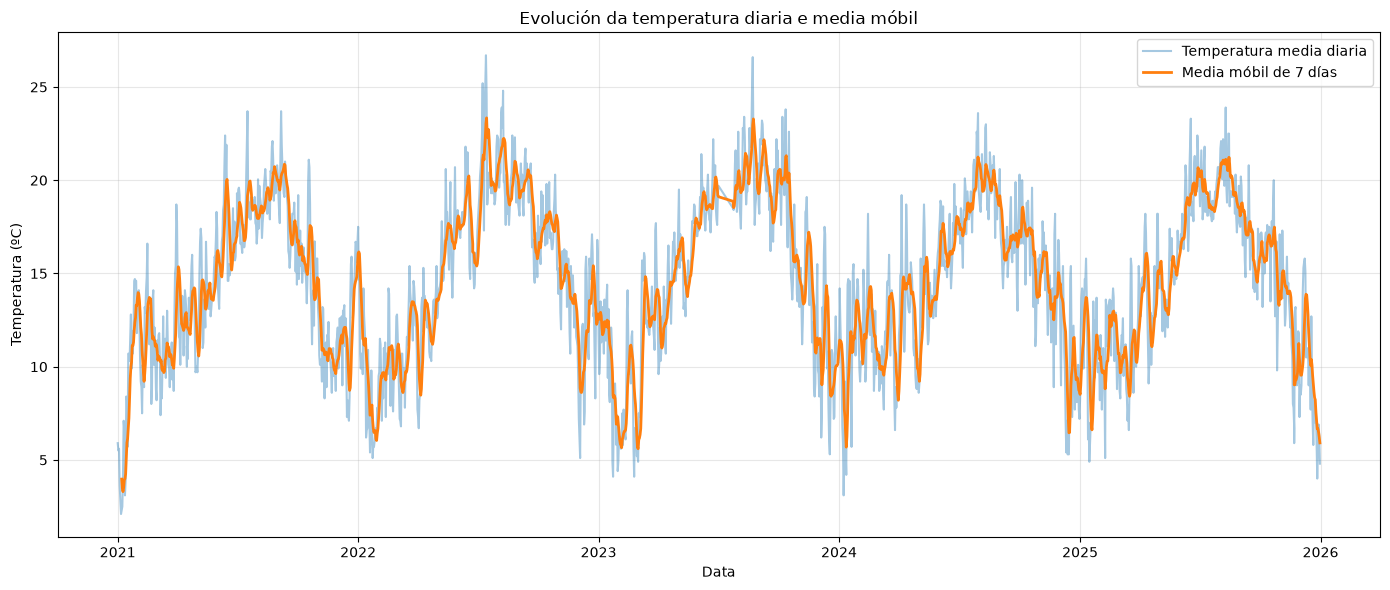

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    df["Data"],
    df["Temp. media (ºC)"],
    label="Temperatura media diaria",
    alpha=0.4
)

plt.plot(
    df["Data"],
    df["Media móbil (7 días)"],
    label="Media móbil de 7 días",
    linewidth=2
)

plt.title("Evolución da temperatura diaria e media móbil")
plt.xlabel("Data")
plt.ylabel("Temperatura (ºC)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Ao comparar ambas as gráficas, obsérvase que a media móbil de 7 días segue máis de preto as variacións da temperatura, mentres que a de 30 días suaviza máis as oscilacións e permite identificar con maior claridade a tendencia xeral ao longo do tempo. Por iso, a gráfica coa media móbil de 30 días resulta máis útil para observar a evolución da temperatura a longo prazo, aínda que perde parte dos cambios máis curtos.

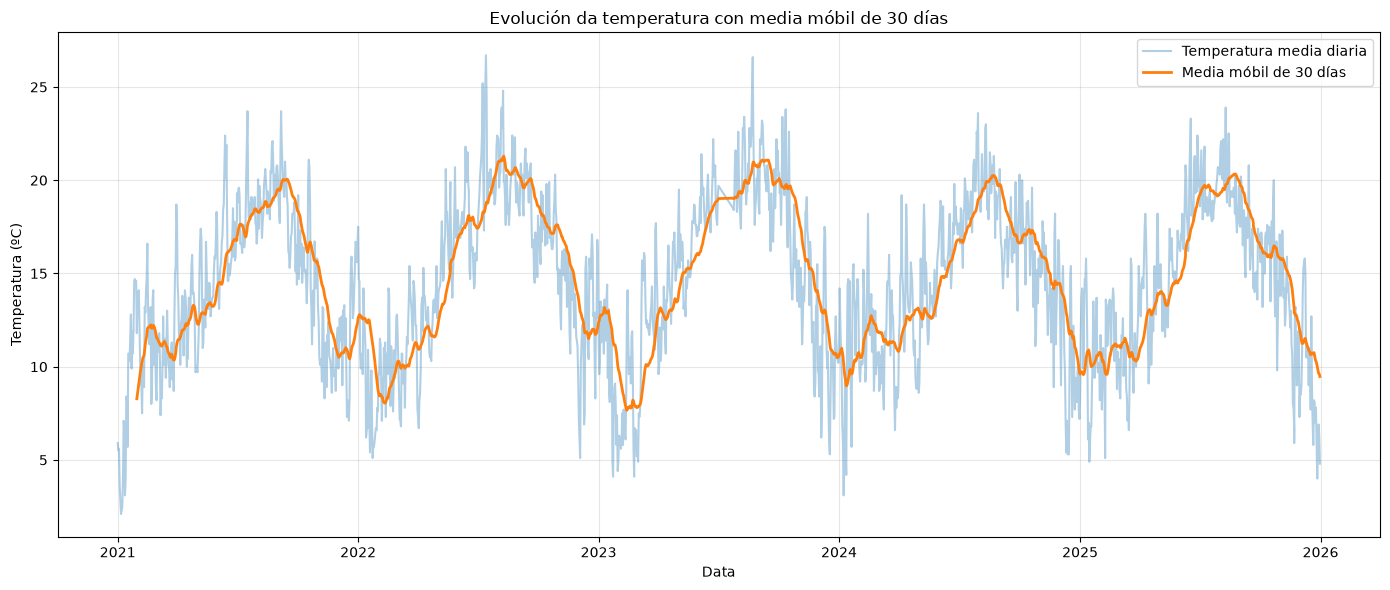

In [7]:
# Ordenar os datos por data
df = df.sort_values("Data").copy()

# Calcular a media móbil de 30 días
df["Media móbil (30 días)"] = (
    df["Temp. media (ºC)"].rolling(window=30).mean()
)

# Representar o gráfico
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    df["Data"],
    df["Temp. media (ºC)"],
    label="Temperatura media diaria",
    alpha=0.35
)

plt.plot(
    df["Data"],
    df["Media móbil (30 días)"],
    label="Media móbil de 30 días",
    linewidth=2
)

plt.title("Evolución da temperatura con media móbil de 30 días")
plt.xlabel("Data")
plt.ylabel("Temperatura (ºC)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Gráfica 2. Humidade relativa de cada mes

### Gráfica da humidade relativa media por mes

Representouse a humidade relativa media para cada mes do ano, agrupando os datos de distintos anos e excluíndo xullo de 2023 debido á presenza de numerosos datos ausentes. Na gráfica non se aprecian diferenzas moi destacadas entre os meses, polo que a representación das medias pode non ser suficiente para comprender completamente o comportamento da humidade ao longo do ano.

Como alternativa, sería interesante empregar un **boxplot** para cada mes. Esta representación permitiría comparar non só os valores centrais, senón tamén a dispersión dos datos, a variabilidade da humidade entre anos e a posible presenza de valores atípicos.

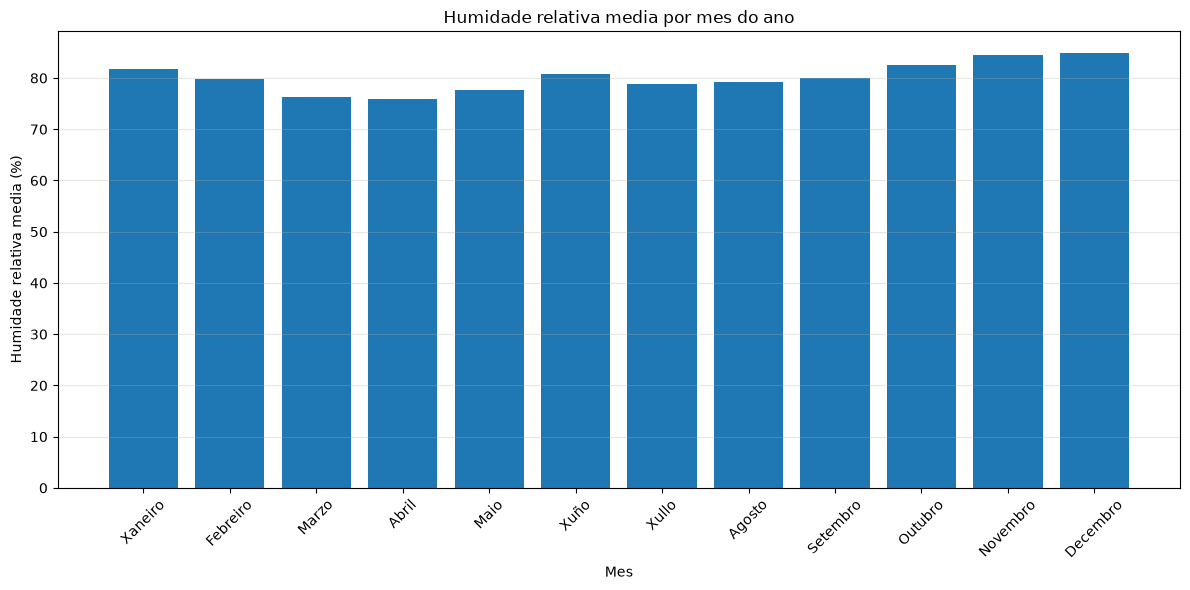

In [10]:
import matplotlib.pyplot as plt

# Excluir julio de 2023
df_filtrado = df[
    ~((df["Data"].dt.year == 2023) &
      (df["Data"].dt.month == 7))
].copy()

# Calcular la media de humedad para cada mes del año,
# agrupando los datos de todos los años
humidade_mensual = (
    df_filtrado.groupby(df_filtrado["Data"].dt.month)
    ["Humidade relativa (%)"]
    .mean()
)

# Nombres de los meses
meses = [
    "Xaneiro", "Febreiro", "Marzo", "Abril",
    "Maio", "Xuño", "Xullo", "Agosto",
    "Setembro", "Outubro", "Novembro", "Decembro"
]

# Gráfica
plt.figure(figsize=(12, 6))

plt.bar(meses, humidade_mensual.reindex(range(1, 13)))

plt.title("Humidade relativa media por mes do ano")
plt.xlabel("Mes")
plt.ylabel("Humidade relativa media (%)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


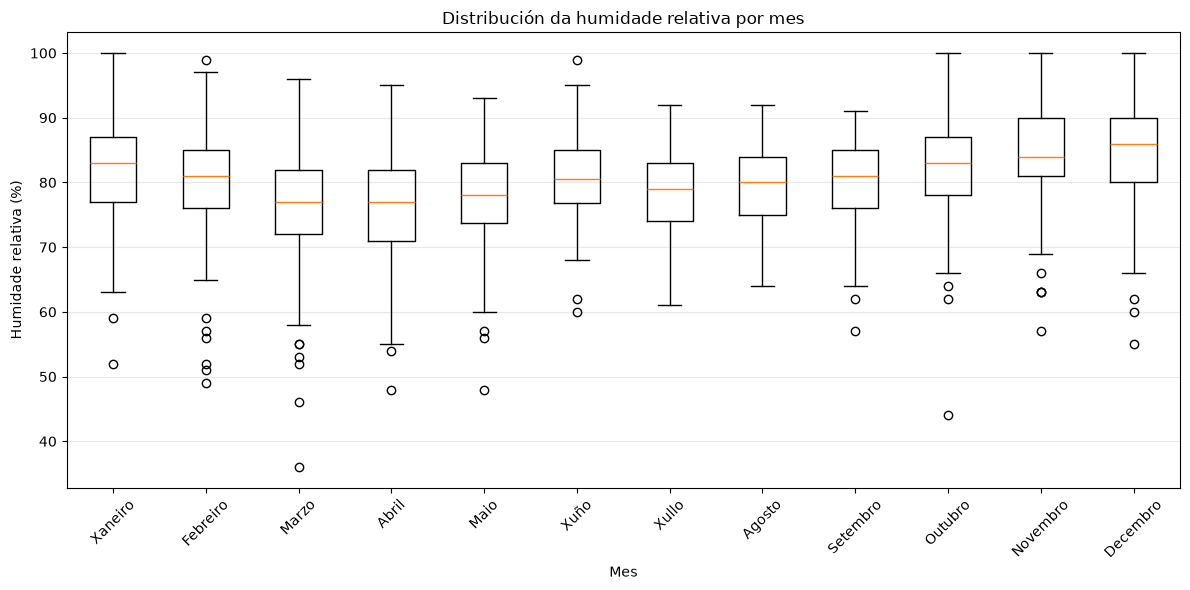

In [15]:

import matplotlib.pyplot as plt

# Excluímos xullo de 2023 polos datos ausentes
df_filtrado = df[
    ~((df["Data"].dt.year == 2023) &
      (df["Data"].dt.month == 7))
].copy()

# Engadimos unha columna co número do mes
df_filtrado["Mes"] = df_filtrado["Data"].dt.month

# Preparamos os datos de humidade de cada mes
datos_boxplot = [
    df_filtrado.loc[
        df_filtrado["Mes"] == mes,
        "Humidade relativa (%)"
    ].dropna()
    for mes in range(1, 13)
]

meses = [
    "Xaneiro", "Febreiro", "Marzo", "Abril",
    "Maio", "Xuño", "Xullo", "Agosto",
    "Setembro", "Outubro", "Novembro", "Decembro"
]

# Creamos o boxplot
plt.figure(figsize=(12, 6))
plt.boxplot(datos_boxplot, tick_labels=meses)

plt.title("Distribución da humidade relativa por mes")
plt.xlabel("Mes")
plt.ylabel("Humidade relativa (%)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


No boxplot non se aprecian diferenzas moi destacadas na distribución da humidade relativa entre os distintos meses. Porén, marzo e abril parecen presentar valores centrais algo máis baixos que o resto dos meses. En xeral, estas diferenzas non parecen moi pronunciadas visualmente, polo que non podemos afirmar que sexan estatisticamente significativas sen realizar unha análise adicional.

## Gráfica 3. Comparación da temperatura mensual do último ano coa media

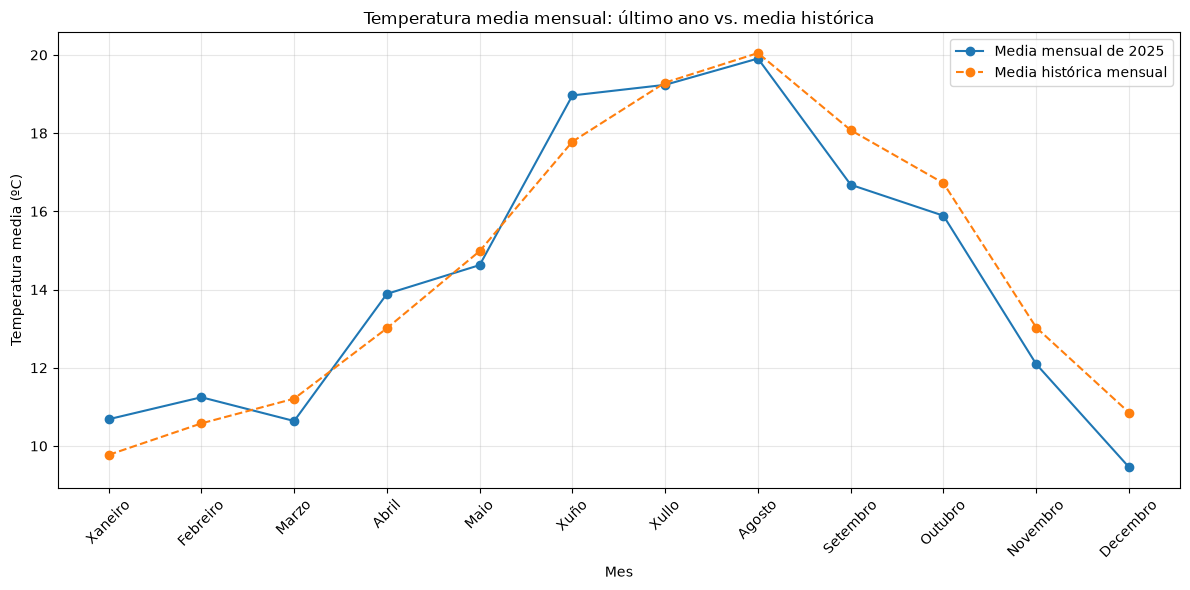

In [11]:

import matplotlib.pyplot as plt

# Excluímos xullo de 2023 porque ten moitos datos ausentes
df_filtrado = df[
    ~((df["Data"].dt.year == 2023) &
      (df["Data"].dt.month == 7))
].copy()

# Identificamos o último ano dispoñible
ultimo_ano = df_filtrado["Data"].dt.year.max()

# Temperatura media de cada mes do último ano
ultimo = df_filtrado[
    df_filtrado["Data"].dt.year == ultimo_ano
].copy()

media_ultimo_ano = (
    ultimo.groupby(ultimo["Data"].dt.month)["Temp. media (ºC)"]
    .mean()
)

# Temperatura media de cada mes considerando todos os anos
media_historica = (
    df_filtrado.groupby(df_filtrado["Data"].dt.month)["Temp. media (ºC)"]
    .mean()
)

# Debuxamos a gráfica
meses = [
    "Xaneiro", "Febreiro", "Marzo", "Abril",
    "Maio", "Xuño", "Xullo", "Agosto",
    "Setembro", "Outubro", "Novembro", "Decembro"
]

plt.figure(figsize=(12, 6))

plt.plot(
    media_ultimo_ano.index,
    media_ultimo_ano.values,
    marker="o",
    label=f"Media mensual de {ultimo_ano}"
)

plt.plot(
    media_historica.index,
    media_historica.values,
    marker="o",
    linestyle="--",
    label="Media histórica mensual"
)

plt.title("Temperatura media mensual: último ano vs. media histórica")
plt.xlabel("Mes")
plt.ylabel("Temperatura media (ºC)")
plt.xticks(range(1, 13), meses, rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Na gráfica non se observan valores moi diferenciados respecto á media da temperatura de meses anteriores. Como moito, nos últimos meses do ano podemos apreciar unha temperaturas lixeiramente máis elevadas que a media. Podemos dicir que o outono do 2025 foi un outono máis quente do normal.

## 4.6 Medición da eficiencia

### Método do bucle for

In [12]:

def amplitude_bucle(df):
    amplitudes = []

    for _, fila in df.iterrows():
        amplitude = fila["Temp. máxima (ºC)"] - fila["Temp. mínima (ºC)"]
        amplitudes.append(amplitude)

    return amplitudes

# Calculamos a amplitude térmica
df["Amplitude térmica (ºC)"] = amplitude_bucle(df)

# Medimos o tempo de execución
%timeit amplitude_bucle(df)


64.9 ms ± 2.03 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


### Método da operación vectorizada con pandas

In [13]:

def amplitude_vectorizada(df):
    return df["Temp. máxima (ºC)"] - df["Temp. mínima (ºC)"]

# Calculamos a amplitude térmica
df["Amplitude térmica vectorizada (ºC)"] = amplitude_vectorizada(df)

# Medimos o tempo de execución
%timeit amplitude_vectorizada(df)


65 μs ± 1.45 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


### Bucle e método vectorizado con dataset 5 veces mais grande

In [14]:

# Creamos un DataFrame con cinco veces máis filas
df_grande = pd.concat([df] * 5, ignore_index=True)

print("Filas do DataFrame orixinal:", len(df))
print("Filas do DataFrame grande:", len(df_grande))

# Medimos o método do bucle
%timeit amplitude_bucle(df_grande)

# Medimos o método vectorizado
%timeit amplitude_vectorizada(df_grande)


Filas do DataFrame orixinal: 1812
Filas do DataFrame grande: 9060
329 ms ± 6.42 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)
71.2 μs ± 1.72 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


### Comentario sobre a eficiencia

Os resultados mostran que a operación vectorizada con pandas é moito máis rápida que o bucle `for`. 

No DataFrame orixinal, o bucle tarda aproximadamente **64,9 ms**, mentres que a operación vectorizada tarda só **65 microsegundos (μs)**, é dicir, uns **0,065 ms**. Polo tanto, a versión vectorizada é arredor de **1.000 veces máis rápida**.

No dataset grande, o tempo do bucle aumenta de 64,9 ms a 329 ms. Pola contra, a operación vectorizada pasa de `65 μs a 71,2 μs`, un incremento `moi pequeno en comparación co do bucle`. 

Isto demostra que as operacións vectorizadas son moito máis eficientes, xa que permiten realizar cálculos sobre columnas sen ter que percorrer as filas unha a unha mediante Python.